In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)
print("TensorFlow Version:", tf.__version__)

print("All libraries imported successfully!")

TensorFlow Version: 2.21.0
All libraries imported successfully!


In [2]:

from google.colab import files

uploaded = files.upload()

Saving cleaned_customerchurn_dataset.csv to cleaned_customerchurn_dataset (2).csv


In [3]:
import pandas as pd
df = pd.read_csv("cleaned_customerchurn_dataset.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [4]:
df.shape

(180, 13)

In [5]:
df.head()

,Customer_ID,Age,Annual_Income,Tenure_Months,Monthly_Charges,Support_Calls_Last_3M,Data_Usage_GB,Satisfaction_Score,Contract_Type,Payment_Method,Region,Plan_Type,Churn
0,CUST-1020,22.0,23800.0,11.0,62.96,7.0,20.4,5.0,Monthly,Bank Transfer,North,Standard,Yes
1,CUST-1043,35.0,69400.0,17.0,75.63,6.0,17.5,9.0,Monthly,Bank Transfer,South,Basic,Yes
2,CUST-1157,55.0,64700.0,49.0,92.85,3.0,21.6,1.0,Monthly,UPI,West,Basic,Yes
3,CUST-1112,36.0,80000.0,9.0,85.67,0.0,34.3,9.0,Monthly,UPI,South,Standard,Yes
4,CUST-1149,41.0,95700.0,51.0,60.77,1.0,23.7,9.0,Monthly,Debit Card,West,Premium,Yes


In [6]:
df.columns

Index(['Customer_ID', 'Age', 'Annual_Income', 'Tenure_Months',
       'Monthly_Charges', 'Support_Calls_Last_3M', 'Data_Usage_GB',
       'Satisfaction_Score', 'Contract_Type', 'Payment_Method', 'Region',
       'Plan_Type', 'Churn'],
      dtype='object')

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Customer_ID            180 non-null    object 
 1   Age                    180 non-null    float64
 2   Annual_Income          180 non-null    float64
 3   Tenure_Months          180 non-null    float64
 4   Monthly_Charges        180 non-null    float64
 5   Support_Calls_Last_3M  180 non-null    float64
 6   Data_Usage_GB          180 non-null    float64
 7   Satisfaction_Score     180 non-null    float64
 8   Contract_Type          180 non-null    object 
 9   Payment_Method         180 non-null    object 
 10  Region                 180 non-null    object 
 11  Plan_Type              180 non-null    object 
 12  Churn                  180 non-null    object 
dtypes: float64(7), object(6)
memory usage: 18.4+ KB


In [8]:
df.describe()

,Age,Annual_Income,Tenure_Months,Monthly_Charges,Support_Calls_Last_3M,Data_Usage_GB,Satisfaction_Score
count,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000
mean,36.311111,65188.333333,38.627778,74.508333,3.055556,18.667222,5.761111
std,8.561502,21655.753296,19.372569,26.184246,1.584570,8.142247,2.811318
min,18.000000,8600.000000,1.000000,0.000000,0.000000,0.800000,1.000000
25%,31.000000,50800.000000,25.000000,58.035000,2.000000,13.150000,4.000000
50%,36.000000,64700.000000,38.000000,72.900000,3.000000,18.800000,6.000000
75%,41.000000,76650.000000,53.250000,88.750000,4.000000,24.125000,8.000000
max,63.000000,120900.000000,72.000000,151.180000,7.000000,44.000000,10.000000


In [9]:
df.isnull().sum()

,0
Customer_ID,0
Age,0
Annual_Income,0
Tenure_Months,0
Monthly_Charges,0
Support_Calls_Last_3M,0
Data_Usage_GB,0
Satisfaction_Score,0
Contract_Type,0
Payment_Method,0


In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df['Churn'].value_counts()

,count
Churn,
Yes,94
No,86


In [12]:
X = df.drop(['Customer_ID', 'Churn'], axis=1)

y = df['Churn']

In [13]:
X = pd.get_dummies(X, drop_first=True, dtype=int)

le = LabelEncoder()

y = le.fit_transform(y)

In [14]:
X.head()

,Age,Annual_Income,Tenure_Months,Monthly_Charges,Support_Calls_Last_3M,Data_Usage_GB,Satisfaction_Score,Contract_Type_2 Year,Contract_Type_Monthly,Payment_Method_Credit Card,Payment_Method_Debit Card,Payment_Method_UPI,Payment_Method_Unknown,Region_North,Region_South,Region_West,Plan_Type_Premium,Plan_Type_Standard
0,22.0,23800.0,11.0,62.96,7.0,20.4,5.0,0,1,0,0,0,0,1,0,0,0,1
1,35.0,69400.0,17.0,75.63,6.0,17.5,9.0,0,1,0,0,0,0,0,1,0,0,0
2,55.0,64700.0,49.0,92.85,3.0,21.6,1.0,0,1,0,0,1,0,0,0,1,0,0
3,36.0,80000.0,9.0,85.67,0.0,34.3,9.0,0,1,0,0,1,0,0,1,0,0,1
4,41.0,95700.0,51.0,60.77,1.0,23.7,9.0,0,1,0,1,0,0,0,0,1,1,0


In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [16]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

In [17]:
print("Training data shape:", X_train.shape)

print("Testing data shape:", X_test.shape)

print("Training target shape:", y_train.shape)

print("Testing target shape:", y_test.shape)

Training data shape: (144, 18)
Testing data shape: (36, 18)
Training target shape: (144,)
Testing target shape: (36,)


## Artificial Neural Network(ANN)

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, SimpleRNN, LSTM, Dropout
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [19]:
model_ann = Sequential()

model_ann.add(Dense(64, activation='relu', input_shape=(18,)))

model_ann.add(Dense(32, activation='relu'))

model_ann.add(Dropout(0.2))

model_ann.add(Dense(16, activation='relu'))

model_ann.add(Dense(1, activation='sigmoid'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [20]:
model_ann.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,841 (15.00 KB)

 Trainable params: 3,841 (15.00 KB)

 Non-trainable params: 0 (0.00 B)

In [21]:
model_ann.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [22]:
history_ann = model_ann.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=16,
    validation_split=0.2,
    verbose=1
)

Epoch 1/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.4435 - loss: 0.7326 - val_accuracy: 0.4828 - val_loss: 0.7070
Epoch 2/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.4609 - loss: 0.6926 - val_accuracy: 0.4828 - val_loss: 0.6945
Epoch 3/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.5478 - loss: 0.6762 - val_accuracy: 0.4483 - val_loss: 0.6848
Epoch 4/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6174 - loss: 0.6467 - val_accuracy: 0.5172 - val_loss: 0.6761
Epoch 5/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6696 - loss: 0.6431 - val_accuracy: 0.6207 - val_loss: 0.6660
Epoch 6/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6522 - loss: 0.6311 - val_accuracy: 0.5862 - val_loss: 0.6591
Epoch 7/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6957 - loss: 0.6083 - val_accuracy: 0.6207 - val_loss: 0.6535
Epoch 8/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6783 - loss: 0.6250 - val_accuracy: 0.6552 - val_loss: 0.6480
Epoch 9

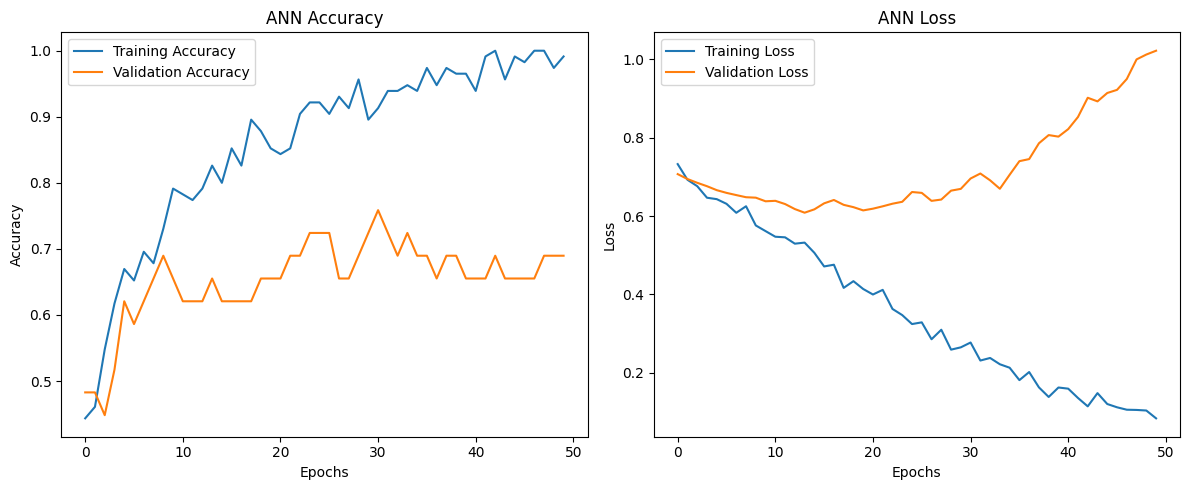

In [23]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history_ann.history['accuracy'], label='Training Accuracy')
plt.plot(history_ann.history['val_accuracy'], label='Validation Accuracy')
plt.title('ANN Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_ann.history['loss'], label='Training Loss')
plt.plot(history_ann.history['val_loss'], label='Validation Loss')
plt.title('ANN Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [24]:
from tensorflow.keras.callbacks import EarlyStopping

model_ann = Sequential([
    Dense(32, activation='relu', input_shape=(18,)),
    Dropout(0.3),
    Dense(16, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='sigmoid')
])

model_ann.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=8,
    restore_best_weights=True
)

history_ann = model_ann.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=16,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.4348 - loss: 0.8246 - val_accuracy: 0.4138 - val_loss: 0.7849
Epoch 2/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.4609 - loss: 0.7408 - val_accuracy: 0.3448 - val_loss: 0.7789
Epoch 3/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.4435 - loss: 0.7485 - val_accuracy: 0.3448 - val_loss: 0.7745
Epoch 4/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.4609 - loss: 0.7669 - val_accuracy: 0.3103 - val_loss: 0.7664
Epoch 5/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.4783 - loss: 0.7411 - val_accuracy: 0.2759 - val_loss: 0.7619
Epoch 6/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.5130 - loss: 0.7081 - val_accuracy: 0.3103 - val_loss: 0.7605
Epoch 7/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6174 - loss: 0.6883 - val_accuracy: 0.4138 - val_loss: 0.7632
Epoch 8/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.5652 - loss: 0.6784 - val_accuracy: 0.4138 - val_loss: 0.761

In [25]:
test_loss, test_accuracy = model_ann.evaluate(X_test, y_test)

print("ANN Test Loss:", test_loss)
print("ANN Test Accuracy:", test_accuracy * 100, "%")

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.4722 - loss: 0.7420
ANN Test Loss: 0.7420145869255066
ANN Test Accuracy: 47.22222089767456 %


In [26]:
y_pred_prob = model_ann.predict(X_test)

y_pred_ann = (y_pred_prob > 0.5).astype(int).ravel()

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step


In [27]:
print(classification_report(y_test, y_pred_ann))

              precision    recall  f1-score   support

           0       0.45      0.59      0.51        17
           1       0.50      0.37      0.42        19

    accuracy                           0.47        36
   macro avg       0.48      0.48      0.47        36
weighted avg       0.48      0.47      0.47        36



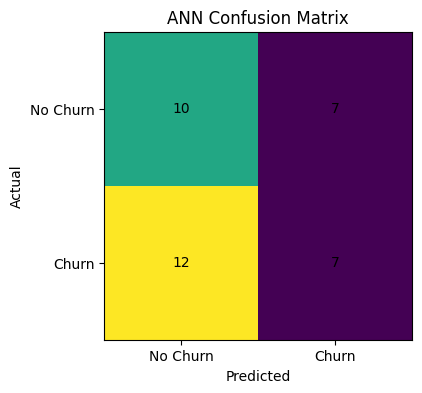

In [28]:
cm = confusion_matrix(y_test, y_pred_ann)

plt.figure(figsize=(6, 4))
plt.imshow(cm)

plt.title("ANN Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.xticks([0, 1], ['No Churn', 'Churn'])
plt.yticks([0, 1], ['No Churn', 'Churn'])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha='center', va='center')

plt.show()